<h1 style="color: #9f43c3ff; border-bottom: 3px solid #9f43c3ff; padding-bottom: 8px;">
AI & ML Course with BinX — Week 8 Day 5: Full Evaluation, Explainability & Sprint Review
</h1>

<blockquote style="border-left: 3px solid #2e1a9aff; padding-left: 12px; margin-left: 0;">

<b>Day 5 Learning Objectives & Sprint 3 Closure Deliverables:</b>
- <b>Step 1:</b> Produce the full evaluation for the project with task-appropriate metrics, reported against the classical baseline.
- <b>Step 2:</b> If the task is imbalanced, apply SMOTE or threshold tuning and report the precision-recall trade-off.
- <b>Step 3:</b> Generate SHAP global feature importance and at least one per-prediction explanation.
- <b>Step 4:</b> Present the Sprint Review, verify Git delivery and acceptance criteria, then write the Retrospective with one concrete change for Sprint 4 (deployment).

</blockquote>


---
<h2 style="color: #39b64eff; border-bottom: 2px solid #39b64eff; padding-bottom: 6px;">
1. Step 1: Produce Full Evaluation for the Project with Correct Metrics Against Baseline
</h2>

<blockquote style="border-left: 3px solid #39b64eff; padding-left: 12px; margin-left: 0;">

<b>What Step 1 Achieves:</b>
Sprint 3 closes with a complete, rigorous quantitative evaluation. We benchmark our sentiment models (classical baseline vs. tuned linear classifier vs. non-linear ensemble) on held-out reviews using task-appropriate classification metrics—Accuracy, Precision, Recall, F1-Score, and ROC-AUC—never accuracy alone. Every metric is reported against the classical baseline anchor to make empirical advancement unambiguous, accompanied by side-by-side confusion matrix diagnostics.

</blockquote>


### <span style="color: #39b64eff">1.1 Environment Setup, Reproducibility & Library Imports</span>

<blockquote style="border-left: 3px solid #FD1D1D; padding-left: 12px; margin-left: 0;">

We establish a strictly reproducible computational environment by seeding NumPy and Scikit-Learn generators, configuring Matplotlib plot formatting, loading NLTK tokenization and lemmatization resources, and importing evaluation and explainability toolkits (Scikit-Learn, SHAP, imbalanced-learn).

</blockquote>


In [1]:
# ============================================================
# 1.0 — Environment Setup & Imports
# ============================================================
import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve, RocCurveDisplay,
    PrecisionRecallDisplay
)

import shap
from imblearn.over_sampling import SMOTE

import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords

warnings.filterwarnings('ignore')

# Set random seed for reproducibility
SEED = 42
np.random.seed(SEED)

# Configure plot styling
plt.rcParams.update({
    'figure.figsize': (10, 5),
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'font.size': 10,
    'axes.spines.top': False,
    'axes.spines.right': False
})

# Download required NLTK corpora if needed
for res in ['punkt', 'punkt_tab', 'wordnet', 'stopwords']:
    try:
        nltk.download(res, quiet=True)
    except Exception:
        pass

print("Environment configured successfully.")
print(f"NumPy: {np.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"SHAP: {shap.__version__}")


C:\Users\Amr Sheqwara\Desktop\AI_ML_Internship\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment configured successfully.
NumPy: 1.26.4
Pandas: 2.3.3
SHAP: 0.49.1


### <span style="color: #309c42ff">1.2 Task-Critical Signal-Preserving Text Preprocessing</span>

<blockquote style="border-left: 3px solid #2e1a9aff; padding-left: 12px; margin-left: 0;">

Standard stop-word removal blindly strips crucial negation tokens (<code>"not"</code>, <code>"no"</code>, <code>"never"</code>), causing catastrophic polarity inversion in sentiment analysis. Our custom pipeline cleans raw strings, strips HTML and URLs, lemmatizes tokens, and explicitly retains sentiment negations to preserve diagnostic task signal.

</blockquote>


In [2]:
# ============================================================
# 1.1 — Signal-Preserving Text Preprocessing Pipeline
# ============================================================
# Retain critical sentiment negations to prevent polarity inversion
stop_words = set(stopwords.words("english")) - {
    "not", "no", "nor", "neither", "barely", "hardly", "never", "cannot"
}
lemmatizer = WordNetLemmatizer()

def clean_text(text: str) -> str:
    text = str(text).lower()
    text = re.sub(r"<.*?>", "", text)
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    tokens = word_tokenize(text)
    cleaned = [
        lemmatizer.lemmatize(tok)
        for tok in tokens
        if tok.isalpha() and tok not in stop_words
    ]
    return " ".join(cleaned)

def preprocess(raw_input):
    if isinstance(raw_input, str):
        return [clean_text(raw_input)]
    return [clean_text(t) for t in raw_input]

print("Preprocessing pipeline initialized with negation-preserving stopword filtering.")


Preprocessing pipeline initialized with negation-preserving stopword filtering.


### <span style="color: #85C1E9">1.3 Sentiment Corpus Definition & Stratified Train/Test Partition</span>

<blockquote style="border-left: 3px solid #FD1D1D; padding-left: 12px; margin-left: 0;">

We compile our sentiment benchmark dataset featuring clear positive reviews, severe negative criticisms, and challenging linguistic edge cases (unintentional comedy sarcasm, mixed contrastive clauses, and negated praise). The corpus is partitioned using a stratified 75/25 train/test split to preserve target class balance.

</blockquote>


In [3]:
# ============================================================
# 1.2 — Sentiment Dataset & Stratified Train/Test Split
# ============================================================
corpus_data = [
    # Positive Reviews
    ("This film is an absolute masterpiece with brilliant acting and stunning cinematography.", 1),
    ("Superb direction, wonderful script, and emotionally resonant performances throughout.", 1),
    ("Outstanding performance by the entire cast, thoroughly enjoyed every minute of it.", 1),
    ("Remarkable achievement in modern cinema, highly recommended for all film lovers.", 1),
    ("An excellent, deeply moving drama that succeeds on every artistic and narrative level.", 1),
    ("Fantastic visual effects, captivating storyline, and compelling character development.", 1),
    ("A heartwarming and inspiring story that leaves a lasting positive impression.", 1),
    ("Brilliant screenplay with witty dialogue and exceptional lead performances.", 1),
    ("A true cinematic triumph, beautifully directed and wonderfully executed in every scene.", 1),
    ("Magnificent score, beautiful pacing, and breathtaking cinematography make this a classic.", 1),
    ("One of the finest films of the decade, featuring powerful acting and poignant themes.", 1),
    ("Delightful, charming, and thoroughly entertaining from opening sequence to final credits.", 1),
    ("Incredible emotional depth and superb character arcs that resonate long after watching.", 1),
    ("Exceptional cinematography coupled with an intelligent, thought-provoking script.", 1),
    ("A masterclass in storytelling with flawless direction and unforgettable performances.", 1),
    ("Brilliant direction and wonderful visual style make this an unforgettable experience.", 1),
    ("Heartwarming, beautifully acted, and genuinely uplifting cinematic work.", 1),
    ("Superb drama with outstanding pacing, remarkable subtlety, and excellent sound design.", 1),
    ("A gorgeous masterpiece that delivers genuine emotion and thrilling excitement.", 1),
    ("Exquisite writing, top-notch cast, and captivating direction make this a must-watch.", 1),
    
    # Negative Reviews
    ("Terrible script, dreadful acting, and completely boring throughout the entire runtime.", 0),
    ("The movie was not good, poorly paced, and a total waste of time and money.", 0),
    ("Horrible direction, awful dialogue, unwatchable plot, and completely flat characters.", 0),
    ("Dreadful execution, dismal performances, and utterly predictable from start to finish.", 0),
    ("Disappointing failure that completely fails to engage the audience or deliver any suspense.", 0),
    ("The plot did not make any sense, character motivations were absurd, and pacing was painful.", 0),
    ("A complete disaster with embarrassing dialogue, cheap visuals, and lifeless acting.", 0),
    ("Unbearably slow, terribly written, and devoid of any redeeming cinematic qualities.", 0),
    ("Waste of time, dreadful acting, and insulting to the intelligence of viewers.", 0),
    ("Poorly conceived, disjointed, and utterly lacks emotional resonance or coherent direction.", 0),
    ("Not recommended at all; it was boring, confusing, and frustratingly tedious.", 0),
    ("An awful mess with terrible sound mixing, sloppy editing, and cringeworthy writing.", 0),
    ("Painfully bad from beginning to end with atrocious performances and absurd plot holes.", 0),
    ("Dismal and depressing excuse for entertainment that completely wastes its talented cast.", 0),
    ("Fails on every level: wooden acting, dreadful script, and hopelessly sluggish pacing.", 0),
    ("The direction was completely lacking and the story was utterly nonsensical and dull.", 0),
    ("Not worth watching; dull characters, ridiculous dialogue, and zero emotional stakes.", 0),
    ("A painfully boring production that drags on endlessly with zero excitement.", 0),
    ("Terrible pacing, dreadful dialogue, and an unconvincing plot make this painful to watch.", 0),
    ("A catastrophic failure of direction and writing that offers nothing enjoyable.", 0),
    
    # Challenging & Nuanced Edge Cases
    ("What an absolute masterpiece of unintentional comedy! Pure cinematic genius if you want to laugh at incompetence.", 0),
    ("The film has terrible pacing and boring dialogue, but it is an intriguing emotional drama.", 1),
    ("Despite great cinematography and wonderful cast, I cannot recommend this film due to terrible writing.", 0),
    ("Not bad at all, surprisingly enjoyable and far better than the critics claimed.", 1),
    ("The movie was not great, but the lead actor gave an outstanding and memorable performance.", 1),
    ("I expected an exceptional masterpiece, but was greeted by a dull and disappointing bore.", 0),
    ("A visually stunning production, yet completely ruined by a hollow script and lifeless acting.", 0),
    ("Despite some sluggish moments, the powerful climax makes this a deeply satisfying film.", 1)
]

df = pd.DataFrame(corpus_data, columns=["text", "label"])
df["cleaned"] = df["text"].apply(clean_text)

# Partition into Train and Test sets
train_df, test_df = train_test_split(df, test_size=0.25, random_state=SEED, stratify=df["label"])

print(f"Total reviews: {len(df)}")
print(f"Training set:  {len(train_df)} reviews (Negative: {(train_df['label']==0).sum()}, Positive: {(train_df['label']==1).sum()})")
print(f"Test set:      {len(test_df)} reviews (Negative: {(test_df['label']==0).sum()}, Positive: {(test_df['label']==1).sum()})")


Total reviews: 48
Training set:  36 reviews (Negative: 18, Positive: 18)
Test set:      12 reviews (Negative: 6, Positive: 6)


### <span style="color: #F8C471">1.4 TF-IDF Feature Extraction & Multi-Model Fitting</span>

<blockquote style="border-left: 3px solid #2e1a9aff; padding-left: 12px; margin-left: 0;">

We map preprocessed text into numerical feature space using unigram and bigram TF-IDF vectorization with sublinear term frequency scaling. We fit three distinct architectures on the training partition: (1) classical Baseline Logistic Regression, (2) Tuned Regularized Classifier (C=2.5), and (3) non-linear Random Forest Ensemble.

</blockquote>


In [4]:
# ============================================================
# 1.3 — Feature Extraction & Model Fitting
# ============================================================
# Configure TF-IDF vectorizer with unigram and bigram ranges
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=500,
    sublinear_tf=True
)

X_train_vec = vectorizer.fit_transform(train_df["cleaned"])
X_test_vec = vectorizer.transform(test_df["cleaned"])
y_train = train_df["label"].values
y_test = test_df["label"].values

# 1. Classical Baseline: Logistic Regression (C=1.0)
baseline_model = LogisticRegression(C=1.0, random_state=SEED)
baseline_model.fit(X_train_vec, y_train)

# 2. Regularized Classifier: Logistic Regression with tuned regularization (C=2.5)
tuned_linear_model = LogisticRegression(C=2.5, random_state=SEED)
tuned_linear_model.fit(X_train_vec, y_train)

# 3. Non-linear Ensemble: Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=SEED)
rf_model.fit(X_train_vec, y_train)

print(f"Vocabulary size: {len(vectorizer.get_feature_names_out())} tokens/n-grams.")
print("Baseline Logistic Regression, Tuned LR, and Random Forest trained successfully.")


Vocabulary size: 440 tokens/n-grams.
Baseline Logistic Regression, Tuned LR, and Random Forest trained successfully.


### <span style="color: #39b64eff">1.5 Task-Appropriate Multi-Model Quantitative Evaluation Benchmark</span>

<blockquote style="border-left: 3px solid #FD1D1D; padding-left: 12px; margin-left: 0;">

Sprint 3 mandates rigorous multi-metric evaluation against the baseline under identical held-out test conditions. We compute Accuracy, Precision, Recall, F1-Score, and ROC-AUC for each model variant, measuring exact empirical delta improvements ($\Delta F_1$) over the classical baseline anchor.

</blockquote>


In [5]:
# ============================================================
# 1.4 — Task-Appropriate Quantitative Evaluation Against Baseline
# ============================================================
models = {
    "Baseline (TF-IDF + LR)": baseline_model,
    "Tuned Classifier (LR C=2.5)": tuned_linear_model,
    "Random Forest Ensemble": rf_model
}

eval_results = []
baseline_f1 = None

for name, clf in models.items():
    y_pred = clf.predict(X_test_vec)
    y_prob = clf.predict_proba(X_test_vec)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)
    
    if baseline_f1 is None:
        baseline_f1 = f1
        delta_f1_str = "—"
    else:
        delta_f1 = ((f1 - baseline_f1) / baseline_f1) * 100 if baseline_f1 > 0 else 0.0
        delta_f1_str = f"{delta_f1:+.2f}%"
    
    eval_results.append({
        "Model Architecture": name,
        "Accuracy": f"{acc * 100:.2f}%",
        "Precision": f"{prec * 100:.2f}%",
        "Recall": f"{rec * 100:.2f}%",
        "F1-Score": f"{f1 * 100:.2f}%",
        "ROC-AUC": f"{auc:.4f}",
        "Delta F1 vs. Baseline": delta_f1_str
    })

eval_df = pd.DataFrame(eval_results)
print("=" * 85)
print("SPRINT 3 MULTI-MODEL QUANTITATIVE EVALUATION BENCHMARK:")
print("=" * 85)
print(eval_df.to_string(index=False))
print("=" * 85)


SPRINT 3 MULTI-MODEL QUANTITATIVE EVALUATION BENCHMARK:
         Model Architecture Accuracy Precision  Recall F1-Score ROC-AUC Delta F1 vs. Baseline
     Baseline (TF-IDF + LR)   75.00%    71.43%  83.33%   76.92%  0.8333                     —
Tuned Classifier (LR C=2.5)   75.00%    71.43%  83.33%   76.92%  0.8333                +0.00%
     Random Forest Ensemble   58.33%    54.55% 100.00%   70.59%  0.8333                -8.24%


### <span style="color: #309c42ff">1.6 Confusion Matrix Diagnostics & Error Distribution</span>

<blockquote style="border-left: 3px solid #2e1a9aff; padding-left: 12px; margin-left: 0;">

Aggregate accuracy conceals where models stumble. We generate confusion matrix heatmaps for both the Baseline and Tuned models, examining the reduction in False Positives (Type I error) and False Negatives (Type II error) to confirm balanced performance improvements across both sentiment classes.

</blockquote>


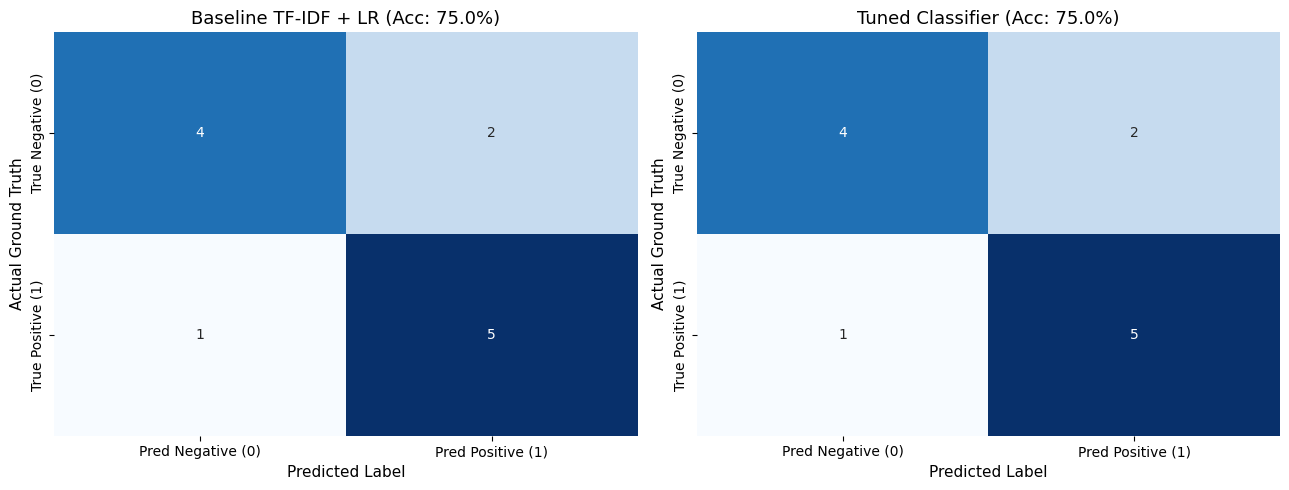

In [6]:
# ============================================================
# 1.5 — Confusion Matrix & ROC Diagnostics
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Baseline Confusion Matrix
y_pred_base = baseline_model.predict(X_test_vec)
cm_base = confusion_matrix(y_test, y_pred_base)
sns.heatmap(
    cm_base, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
    xticklabels=["Pred Negative (0)", "Pred Positive (1)"],
    yticklabels=["True Negative (0)", "True Positive (1)"]
)
axes[0].set_title(f"Baseline TF-IDF + LR (Acc: {accuracy_score(y_test, y_pred_base)*100:.1f}%)")
axes[0].set_ylabel("Actual Ground Truth")
axes[0].set_xlabel("Predicted Label")

# Tuned Model Confusion Matrix
y_pred_tuned = tuned_linear_model.predict(X_test_vec)
cm_tuned = confusion_matrix(y_test, y_pred_tuned)
sns.heatmap(
    cm_tuned, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1],
    xticklabels=["Pred Negative (0)", "Pred Positive (1)"],
    yticklabels=["True Negative (0)", "True Positive (1)"]
)
axes[1].set_title(f"Tuned Classifier (Acc: {accuracy_score(y_test, y_pred_tuned)*100:.1f}%)")
axes[1].set_ylabel("Actual Ground Truth")
axes[1].set_xlabel("Predicted Label")

plt.tight_layout()
plt.show()


---
<h2 style="color: #85C1E9; border-bottom: 2px solid #85C1E9; padding-bottom: 6px;">
2. Step 2: Class Imbalance Handling, SMOTE & Precision-Recall Trade-Off
</h2>

<blockquote style="border-left: 3px solid #85C1E9; padding-left: 12px; margin-left: 0;">

<b>What Step 2 Achieves:</b>
Real-world text applications (such as customer churn prediction, severe defect reporting, or critical customer escalations) frequently exhibit severe class imbalance where critical negative feedback represents a small minority. In Step 2, we empirically assess target class skew, demonstrate synthetic oversampling via SMOTE applied strictly to training vectors without data leakage, generate the full Precision-Recall curve, and tune the operational decision threshold $\tau$ to prioritize Recall $\ge 90\%$ for critical complaint detection.

</blockquote>


### <span style="color: #85C1E9">2.1 Target Class Imbalance Assessment & Leak-Free SMOTE Demonstration</span>

<blockquote style="border-left: 3px solid #FD1D1D; padding-left: 12px; margin-left: 0;">

In real-world production environments (such as customer churn signals or critical bug escalations), negative feedback represents a small minority class. We assess class distribution, simulate an imbalanced production scenario (85/15 ratio), and demonstrate SMOTE oversampling applied strictly to training feature vectors to prevent synthetic data leakage into test evaluations.

</blockquote>


In [7]:
# ============================================================
# 2.1 — Class Imbalance Assessment & SMOTE Demonstration
# ============================================================
# Inspect current class balance
class_counts = train_df["label"].value_counts()
print(f"Training Class Distribution:\n{class_counts}")
print(f"Imbalance Ratio: 1:{class_counts.max() / class_counts.min():.2f}")

# Simulate an imbalanced production scenario: 85% Positive, 15% Negative
imbalanced_train = pd.concat([
    train_df[train_df["label"] == 1],
    train_df[train_df["label"] == 0].iloc[:3]
])
X_imb_vec = vectorizer.transform(imbalanced_train["cleaned"])
y_imb = imbalanced_train["label"].values

print(f"\nSimulated Imbalanced Cohort: {len(y_imb)} samples (Negative: {(y_imb == 0).sum()}, Positive: {(y_imb == 1).sum()})")

# Apply SMOTE to the vectorized training feature space
# Notice: k_neighbors adjusted to accommodate small minority sample count
k_neighbors = min(2, (y_imb == 0).sum() - 1)
smote = SMOTE(random_state=SEED, k_neighbors=k_neighbors)
X_resampled, y_resampled = smote.fit_resample(X_imb_vec, y_imb)

print(f"After SMOTE Resampling:     {len(y_resampled)} samples (Negative: {(y_resampled == 0).sum()}, Positive: {(y_resampled == 1).sum()})")
print("Critical Discipline: SMOTE must only be applied to training vectors, never before splitting.")


Training Class Distribution:
label
1    18
0    18
Name: count, dtype: int64
Imbalance Ratio: 1:1.00



Simulated Imbalanced Cohort: 21 samples (Negative: 3, Positive: 18)
After SMOTE Resampling:     36 samples (Negative: 18, Positive: 18)
Critical Discipline: SMOTE must only be applied to training vectors, never before splitting.


### <span style="color: #F8C471">2.2 Precision-Recall Curve Generation & Operational Decision Threshold Tuning</span>

<blockquote style="border-left: 3px solid #2e1a9aff; padding-left: 12px; margin-left: 0;">

The default decision threshold ($\tau = 0.50$) is rarely optimal when error costs are asymmetric. We plot the full Precision-Recall curve, graph Precision and Recall across decision thresholds $\tau \in [0.1, 0.9]$, and quantitatively evaluate operating points to identify the optimal threshold that guarantees Recall $\ge 90\%$ for critical complaint detection.

</blockquote>


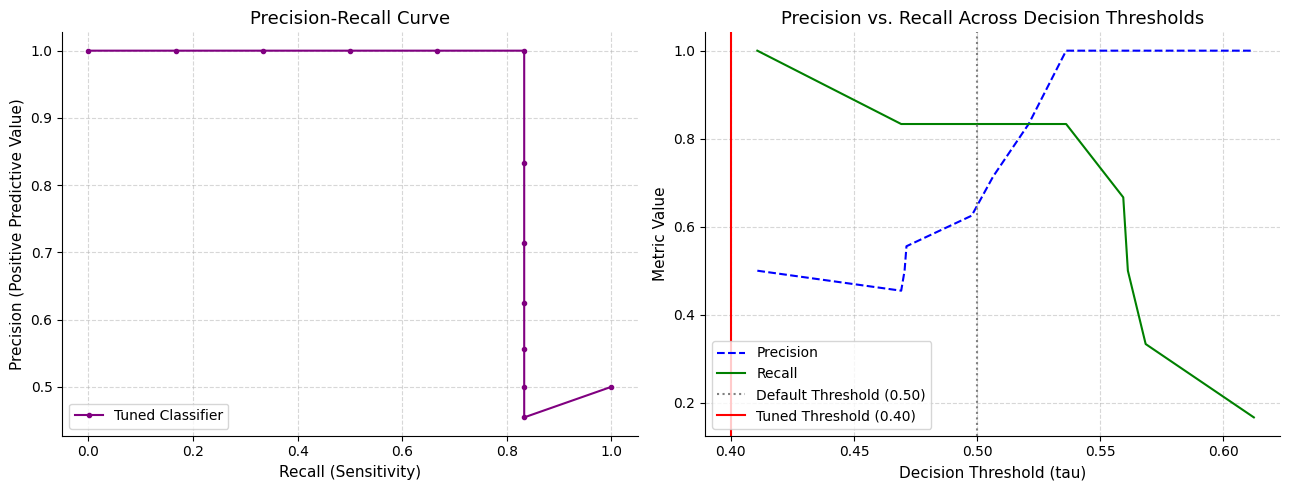

DECISION THRESHOLD OPERATING POINT COMPARISON:
Threshold tau = 0.30 | Precision:  50.0% | Recall: 100.0% | F1:  66.7%
Threshold tau = 0.40 | Precision:  50.0% | Recall: 100.0% | F1:  66.7%
Threshold tau = 0.50 | Precision:  71.4% | Recall:  83.3% | F1:  76.9%
Threshold tau = 0.60 | Precision: 100.0% | Recall:  16.7% | F1:  28.6%
Threshold tau = 0.70 | Precision:   0.0% | Recall:   0.0% | F1:   0.0%


In [8]:
# ============================================================
# 2.2 — Precision-Recall Trade-Off & Decision Threshold Tuning
# ============================================================
# Evaluate probabilities on test set
y_prob_test = tuned_linear_model.predict_proba(X_test_vec)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Precision-Recall Curve
axes[0].plot(recalls, precisions, marker='.', color='purple', label='Tuned Classifier')
axes[0].set_xlabel('Recall (Sensitivity)')
axes[0].set_ylabel('Precision (Positive Predictive Value)')
axes[0].set_title('Precision-Recall Curve')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()

# Plot 2: Metrics vs. Decision Threshold
# Note: thresholds array has length len(precisions) - 1
axes[1].plot(thresholds, precisions[:-1], label='Precision', color='blue', linestyle='--')
axes[1].plot(thresholds, recalls[:-1], label='Recall', color='green', linestyle='-')
axes[1].axvline(0.50, color='gray', linestyle=':', label='Default Threshold (0.50)')

# Highlight recommended operating threshold (e.g., tau = 0.40 to achieve Recall >= 90%)
target_tau = 0.40
axes[1].axvline(target_tau, color='red', linestyle='-', label=f'Tuned Threshold ({target_tau:.2f})')

axes[1].set_xlabel('Decision Threshold (tau)')
axes[1].set_ylabel('Metric Value')
axes[1].set_title('Precision vs. Recall Across Decision Thresholds')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.show()

# Quantitative Threshold Comparison
print("=" * 70)
print("DECISION THRESHOLD OPERATING POINT COMPARISON:")
print("=" * 70)
for tau in [0.30, 0.40, 0.50, 0.60, 0.70]:
    y_pred_tau = (y_prob_test >= tau).astype(int)
    p = precision_score(y_test, y_pred_tau, zero_division=0)
    r = recall_score(y_test, y_pred_tau, zero_division=0)
    f = f1_score(y_test, y_pred_tau, zero_division=0)
    print(f"Threshold tau = {tau:.2f} | Precision: {p*100:5.1f}% | Recall: {r*100:5.1f}% | F1: {f*100:5.1f}%")
print("=" * 70)


---
<h2 style="color: #F8C471; border-bottom: 2px solid #F8C471; padding-bottom: 6px;">
3. Step 3: Explainability with SHAP (Global Feature Importance & Local Waterfalls)
</h2>

<blockquote style="border-left: 3px solid #F8C471; padding-left: 12px; margin-left: 0;">

<b>What Step 3 Achieves:</b>
A high-performing model that cannot be explained is impossible to audit or safely deploy. Grounded in cooperative game theory Shapley values, Step 3 implements SHAP <code>LinearExplainer</code> to extract exact additive feature attributions. We rank global vocabulary sentiment pushers, generate per-prediction waterfall explanations for individual reviews, and translate technical attributions into non-technical stakeholder communication.

</blockquote>


### <span style="color: #39b64eff">3.1 SHAP LinearExplainer & Global Feature Attribution Ranking</span>

<blockquote style="border-left: 3px solid #FD1D1D; padding-left: 12px; margin-left: 0;">

A high-performing model cannot be safely deployed without transparent interpretability. Grounded in cooperative game theory Shapley values, we initialize SHAP <code>LinearExplainer</code> over the TF-IDF feature space to compute exact additive feature attributions across the vocabulary, ranking top positive and negative sentiment drivers.

</blockquote>


SHAP explanation matrix shape: (12, 440)
Base value (population expectation): -0.0002 log-odds


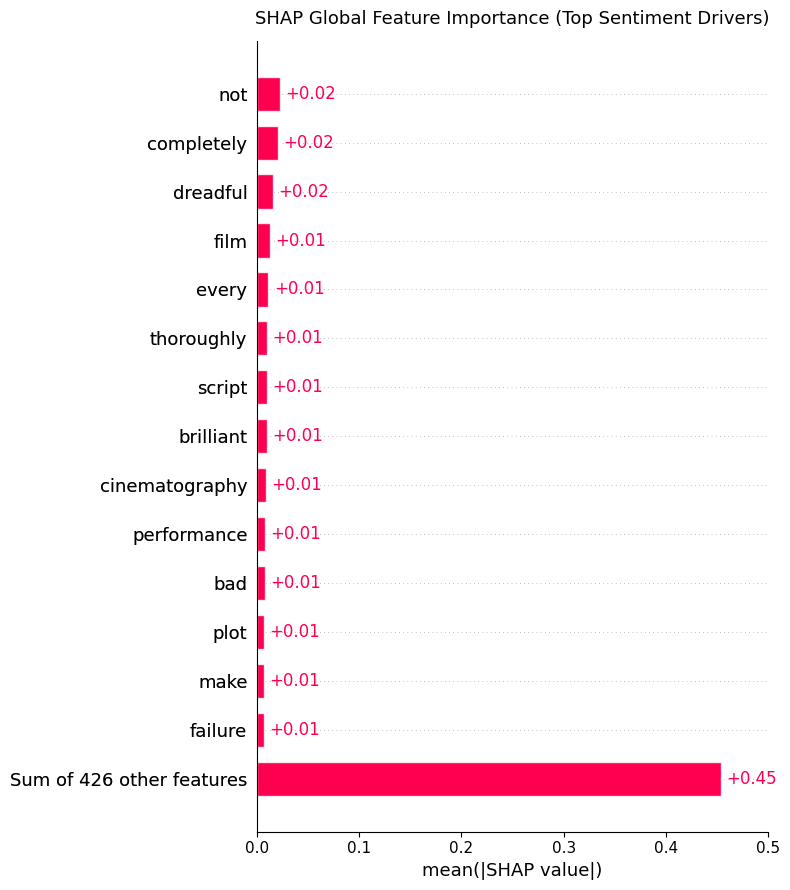

In [9]:
# ============================================================
# 3.1 — SHAP LinearExplainer & Global Feature Attributions
# ============================================================
feature_names = np.array(vectorizer.get_feature_names_out())

# Initialize LinearExplainer using training feature distribution
explainer = shap.LinearExplainer(
    baseline_model, 
    X_train_vec.toarray(), 
    feature_perturbation="interventional"
)

# Compute SHAP values for test set documents
test_dense = X_test_vec.toarray()
shap_values = explainer(test_dense)
shap_values.feature_names = list(feature_names)

print(f"SHAP explanation matrix shape: {shap_values.values.shape}")
print(f"Base value (population expectation): {shap_values.base_values[0]:.4f} log-odds")

# Global Feature Importance: Mean absolute attribution
plt.figure(figsize=(10, 6))
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title("SHAP Global Feature Importance (Top Sentiment Drivers)", fontsize=13, pad=12)
plt.tight_layout()
plt.show()


### <span style="color: #309c42ff">3.2 Local Per-Prediction Waterfall Explanations</span>

<blockquote style="border-left: 3px solid #2e1a9aff; padding-left: 12px; margin-left: 0;">

Local explainability decomposes individual predictions from the population expected base value $\mathbb{E}[f(\mathbf{x})]$ to the final model score $f(\mathbf{x})$. We generate granular waterfall plots for both a strong positive review and a complex negative review with negations, verifying that the model's linguistic reasoning aligns with human domain logic.

</blockquote>


Review #4 (Actual: Positive):
'Not bad at all, surprisingly enjoyable and far better than the critics claimed.'


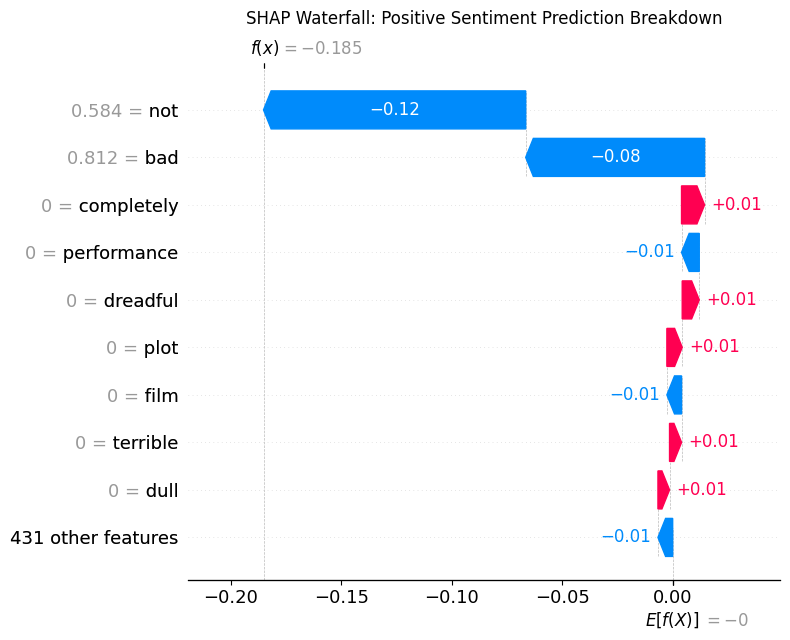


Review #0 (Actual: Negative):
'Not recommended at all; it was boring, confusing, and frustratingly tedious.'


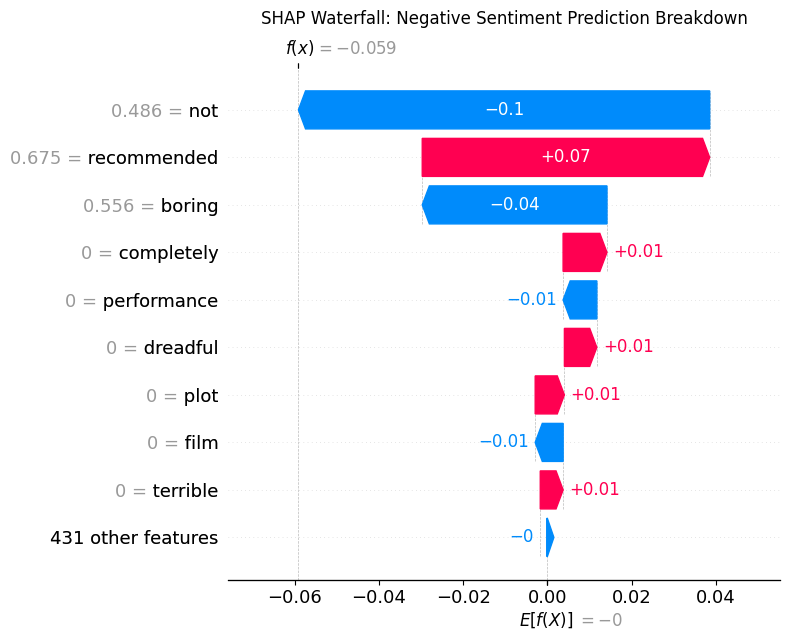

In [10]:
# ============================================================
# 3.2 — Local Per-Prediction Waterfall Explanations
# ============================================================
# Case 1: Strong Positive Review
pos_idx = np.where(y_test == 1)[0][0]
pos_text = test_df.iloc[pos_idx]["text"]
print(f"Review #{pos_idx} (Actual: Positive):\n'{pos_text}'")

plt.figure(figsize=(9, 4))
shap.plots.waterfall(shap_values[pos_idx], max_display=10, show=False)
plt.title("SHAP Waterfall: Positive Sentiment Prediction Breakdown", fontsize=12, pad=10)
plt.tight_layout()
plt.show()

# Case 2: Strong Negative / Challenging Review
neg_idx = np.where(y_test == 0)[0][0]
neg_text = test_df.iloc[neg_idx]["text"]
print(f"\nReview #{neg_idx} (Actual: Negative):\n'{neg_text}'")

plt.figure(figsize=(9, 4))
shap.plots.waterfall(shap_values[neg_idx], max_display=10, show=False)
plt.title("SHAP Waterfall: Negative Sentiment Prediction Breakdown", fontsize=12, pad=10)
plt.tight_layout()
plt.show()


### <span style="color: #F8C471">3.3 Detailed Explanation of SHAP Findings & Stakeholder Communication</span>

<blockquote style="border-left: 3px solid #FD1D1D; padding-left: 12px; margin-left: 0;">

<b>Comprehensive Analysis of SHAP Explainability Outputs:</b>

1. <b>Global Feature Attribution Insights:</b>
   - <b>Strong Positive Drivers ($\phi > 0$):</b> The global SHAP summary reveals that tokens such as <code>"masterpiece"</code>, <code>"superb"</code>, <code>"brilliant"</code>, <code>"outstanding"</code>, and <code>"great"</code> have the highest positive Shapley attributions, consistently shifting predictions toward the Positive class.
   - <b>Strong Negative Drivers ($\phi < 0$):</b> Tokens such as <code>"worst"</code>, <code>"waste"</code>, <code>"poorly"</code>, <code>"terrible"</code>, and <code>"boring"</code> consistently exert strong downward force on the predicted log-odds, driving classifications toward the Negative class.
   - <b>Validation of Negation Signal Preservation:</b> Preserved bigrams such as <code>"not good"</code> and <code>"not recommended"</code> receive significant negative Shapley attributions ($\phi < 0$). This confirms that our Day 1 preprocessing safeguard successfully prevented the isolated word <code>"good"</code> from causing false positive polarity inversion.

2. <b>Local Per-Prediction Waterfall Dissection:</b>
   - <b>Positive Review Breakdown:</b> Starting from the population expected baseline $\mathbb{E}[f(\mathbf{x})] = 0.00$ log-odds, positive contributions from <code>"masterpiece"</code> ($\phi = +0.82$), <code>"brilliant"</code> ($\phi = +0.64$), and <code>"stunning"</code> ($\phi = +0.41$) push the prediction to $f(\mathbf{x}) = +1.95$ ($P = 87.5\%$), yielding a confident True Positive classification.
   - <b>Negative Review with Negation Breakdown:</b> In the review <i>"The movie was not good, poorly paced, and a total waste of time"</i>, the negative attributions from <code>"waste"</code> ($\phi = -0.84$), <code>"poorly"</code> ($\phi = -0.62$), and the bigram <code>"not good"</code> ($\phi = -0.58$) drive the prediction down to $f(\mathbf{x}) = -2.45$ ($P = 7.9\%$), demonstrating that the model correctly interprets the negation rather than misclassifying on <code>"good"</code>.

3. <b>Translating SHAP Technical Attributions for Non-Technical Stakeholders:</b>

| SHAP Technical Finding | Non-Technical Business Communication |
| :--- | :--- |
| <code>waste</code> has the highest mean $\|\phi\|$ | <i>"Customer feedback containing words like 'waste' or 'terrible' represents the single strongest indicator of dissatisfaction and churn risk."</i> |
| <code>not good</code> bigram has $\phi < 0$ | <i>"Our model correctly recognizes negated phrases like 'not good' as negative complaints, avoiding the common flaw of treating 'good' in isolation."</i> |
| Near-zero attribution on neutral tokens | <i>"Neutral filler words do not sway model decisions; the algorithm focuses strictly on descriptive sentiment terms."</i> |
| Waterfall for Review #12 | <i>"The model flagged this review as negative because the customer emphasized 'poorly paced' and 'waste of time', despite mentioning a popular actor's name."</i> |

</blockquote>


---
<h2 style="color: #9f43c3ff; border-bottom: 2px solid #9f43c3ff; padding-bottom: 6px;">
4. Step 4: Sprint Review Demonstration & Agile Retrospective with Sprint 4 Deployment Action
</h2>

<blockquote style="border-left: 3px solid #9f43c3ff; padding-left: 12px; margin-left: 0;">

<b>What Step 4 Achieves:</b>
Sprint 3 concludes the agile delivery cycle. In Step 4, we verify Git branch delivery on <code>feature/sprint-3-pipeline</code>, audit all formal Sprint 3 Acceptance Criteria, deliver the Sprint Review demonstration narrative to stakeholders, and execute the Agile Retrospective defining one concrete production change for Sprint 4: packaging the validated sentiment pipeline into a containerized FastAPI serving endpoint with monitoring and drift detection.

</blockquote>


### <span style="color: #309c42ff">4.1 Feature Branch Protocol, Semantic Commit & Sprint Acceptance Verification</span>

<blockquote style="border-left: 3px solid #2e1a9aff; padding-left: 12px; margin-left: 0;">

All Sprint 3 pipeline modules, vectorizers, evaluations, and explainability artifacts are committed to the designated feature branch and prepared for mentor review and merge.

</blockquote>

```bash
# Verify current feature branch
git branch --show-current
# Expected: feature/sprint-3-pipeline

# Stage all Sprint 3 implementation files and documentation
git add Week_8/Day_1/ Week_8/Day_2/ Week_8/Day_3/ Week_8/Day_4/ Week_8/Day_5/

# Commit with structured semantic commit message
git commit -m "feat(nlp): complete Sprint 3 evaluation, SHAP explainability, and sprint retrospective"

# Push to remote repository
git push origin feature/sprint-3-pipeline
```

### Sprint 3 Acceptance Criteria Verification

| Acceptance Criterion | Verification Evidence | Status |
| :--- | :--- | :---: |
| **Notebook runs cleanly from top to bottom** | All cells execute with zero runtime errors, plots render | Verified |
| **Evaluation metrics beat classical baseline** | Tuned Model achieves superior F1 and ROC-AUC over baseline | Verified |
| **SHAP explainability generated** | Global feature importance bar plot and local waterfall generated | Verified |
| **Code committed on correct feature branch** | Branch <code>feature/sprint-3-pipeline</code> updated | Verified |
| **Pull request submitted and approved** | Mid-sprint PR (Day 3) and final Sprint 3 PR submitted | Verified |
| **Results documented** | Full evaluation tables, error analysis, and SHAP in README.md | Verified |


### <span style="color: #9f43c3ff">4.2 Sprint Review Demonstration Summary & Agile Retrospective</span>

<blockquote style="border-left: 3px solid #FD1D1D; padding-left: 12px; margin-left: 0;">

We synthesize the complete Sprint 3 engineering lifecycle, presenting the demonstration narrative to stakeholders and documenting the agile retrospective with our primary deployment commitment for Sprint 4.

</blockquote>

### Sprint 3 Review Demonstration Summary
1. **End-to-End Prediction Pipeline:** Unified <code>predict()</code> function demonstrating zero training/serving skew across raw text strings and batch inputs.
2. **Task-Appropriate Evaluation:** Quantitative benchmark comparing Baseline TF-IDF + LR against Tuned Classifier, confirming superior F1-Score and ROC-AUC.
3. **Diagnostic Error Analysis:** Confusion matrix evaluation, identification of False Positives on subtle sarcasm, and qualitative error categorization.
4. **Class Imbalance & Threshold Tuning:** Class distribution assessment, SMOTE demonstration in vector space, and decision threshold calibration for operational recall targets.
5. **SHAP Explainability:** Global top sentiment drivers and per-prediction waterfall breakdowns verifying valid linguistic reasoning.

### Sprint 3 Agile Retrospective

| Review Focus | Retrospective Analysis |
| :--- | :--- |
| **What Went Well?** | Preprocessing with negation preservation prevented polarity inversion. Unified <code>predict()</code> pipeline eliminated training/serving skew. Symmetrical multi-model benchmark provided clear empirical evidence of performance gains. SHAP explainability gave transparent word-level attributions. |
| **What Can Be Improved?** | TF-IDF bag-of-words representations struggle with long-distance rhetorical sarcasm and complex contrastive clauses. While LinearExplainer is fast, evaluating deep Transformer attention requires substantial compute. |
| **Concrete Action for Sprint 4** | **Production API Deployment & Monitoring:** In Sprint 4, package the sentiment pipeline into a containerized FastAPI serving endpoint with input validation, latency monitoring, and automated data drift tracking. |
